# [RQ_2, RQ_3 · CHÍNH] XGBoost A/B theo RMSE · Huy · 17/11/2026

Thí nghiệm tiếp nối V3 trong `notebooks/separate/V_3.ipynb`. Giữ cách chia theo thời gian và tiền xử lý trong từng fold. Chọn siêu tham số theo RMSE CV trung bình và ghi MAE để theo dõi sự đánh đổi.

A gồm thời gian và ngày lễ. B thêm thời tiết cùng giờ, với giả định các biến này có sẵn khi dự đoán. Hai cấu hình dùng cùng lưới, fold và giờ validation. Random Forest A/B ngày 17/11 là đối chứng khi khớp cả timestamp và lưu lượng thực tế.

**Nguồn dữ liệu chung (19/11/2026):** Code đọc dữ liệu đã chuyển sang `src.experiment_data.load_experiment_splits`. `processed` dùng snapshot bàn giao; `raw` dùng cho CV trước điền thiếu; `filled` giữ schema nhãn và học điền từ train. Các output/metrics đang hiển thị là kết quả lịch sử, chưa chạy lại sau thay đổi này.


In [1]:
from hashlib import file_digest
import json
from pathlib import Path
import sys

start = Path.cwd().resolve()
project = next(path for path in (start, *start.parents) if (path / "src" / "data.py").is_file())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))

from IPython.display import Image, display
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from sklearn.model_selection import ParameterGrid, TimeSeriesSplit
import xgboost

from src.data import DATA_PATH, fill_missing_weather
from src.evaluation import clip_prediction, regression_metrics, weekday_hour_baseline
from src.features import CONFIG_A, CONFIG_B, add_time_features, add_weather_features
from src.models import make_model
from src.tuning import N_SPLITS, describe_folds

experiment = project / "experiments" / "17-11-2026_Huy_XGBoost_RMSE"
reference = project / "experiments" / "17-11-2026_Huy_Xulydulieu" / "outputs"
data_path = DATA_PATH if DATA_PATH.is_file() else project / "files" / "Metro_Interstate_Traffic_Volume.csv.gz"
data_params = {"mask_stuck_temp": False, "complete_holidays": False}
features = {"A": list(CONFIG_A), "B": list(CONFIG_B)}
fixed_params = {
    "n_estimators": 400,
    "objective": "reg:squarederror",
    "tree_method": "hist",
    "random_state": 42,
    "learning_rate": 0.03,
    "subsample": 0.7,
    "colsample_bytree": 0.8,
    "n_jobs": 4,
}
grid = {
    "max_depth": [4, 6],
    "min_child_weight": [5, 10],
    "reg_lambda": [1, 5, 15],
}
candidates = list(ParameterGrid(grid))

In [2]:
def prepare_pair(raw_fit, raw_score):
    """Học thống kê thời tiết từ phần fit rồi tạo hai bảng đặc trưng."""
    filled = fill_missing_weather({"train": raw_fit, "validation": raw_score})
    return tuple(
        add_weather_features(add_time_features(filled[name])).set_index(
            "date_time", verify_integrity=True
        )
        for name in ("train", "validation")
    )

def check_pair(raw_fit, raw_score, fit, score):
    """Kiểm tra hai cấu hình dùng cùng tập giờ và cùng đặc trưng thời gian."""
    for raw, frame in ((raw_fit, fit), (raw_score, score)):
        expected = raw.set_index("date_time", verify_integrity=True)["traffic_volume"]
        pd.testing.assert_series_equal(frame["traffic_volume"], expected)
        a, b = frame[features["A"]], frame[features["B"]]
        pd.testing.assert_index_equal(a.index, b.index, exact=True)
        pd.testing.assert_frame_equal(a, b[features["A"]])
        if not frame.index.is_monotonic_increasing or frame.index.hasnans:
            raise ValueError("Timestamp phải tăng dần và đầy đủ.")
        if b.isna().any().any():
            raise ValueError("Có giá trị thiếu trong đặc trưng.")
    if fit.index.max() >= score.index.min():
        raise ValueError("Phần fit phải kết thúc trước phần chấm.")

from src.experiment_data import load_experiment_splits
splits = load_experiment_splits(data_path, **data_params, stage="raw")
raw_train, raw_validation = splits["train"], splits["validation"]
train, validation = prepare_pair(raw_train, raw_validation)
check_pair(raw_train, raw_validation, train, validation)

rf = pd.read_csv(reference / "validation_predictions.csv", parse_dates=["date_time"])
rf = rf.set_index("date_time", verify_integrity=True)
pd.testing.assert_index_equal(rf.index, validation.index, exact=True)
pd.testing.assert_series_equal(rf["traffic_volume"], validation["traffic_volume"])

folds = []
fold_manifest = describe_folds(raw_train)
for fit_idx, score_idx in TimeSeriesSplit(n_splits=N_SPLITS).split(raw_train):
    raw_fit, raw_score = raw_train.iloc[fit_idx], raw_train.iloc[score_idx]
    fit, score = prepare_pair(raw_fit, raw_score)
    check_pair(raw_fit, raw_score, fit, score)
    folds.append((fit, score))
print(f"A, B và Random Forest cũ khớp cả {len(validation):,} giờ và mục tiêu validation.")
display(fold_manifest)

A, B và Random Forest cũ khớp cả 6,086 giờ và mục tiêu validation.


notebook cell 2:5: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
notebook cell 2:5: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
notebook cell 2:14: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
notebook cell 2:14: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
notebook cell 2:32: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
notebook cell 2:5: Pan

,fold,fit_start,fit_end,validation_start,validation_end,n_fit,n_validation
0,1,2012-10-02 09:00:00,2013-08-18 18:00:00,2013-08-18 19:00:00,2015-07-07 11:00:00,7102,7100
1,2,2012-10-02 09:00:00,2015-07-07 11:00:00,2015-07-07 12:00:00,2016-07-15 04:00:00,14202,7100
2,3,2012-10-02 09:00:00,2016-07-15 04:00:00,2016-07-15 05:00:00,2017-05-10 04:00:00,21302,7100


In [3]:
def train_xgboost(columns, params, frame):
    model = make_model("XGBoost", columns).set_params(**fixed_params, **params)
    return model.fit(frame[columns], frame["traffic_volume"])

fold_rows = []
for config, columns in features.items():
    for candidate_id, params in enumerate(candidates, start=1):
        for fold, (fit, score) in enumerate(folds, start=1):
            model = train_xgboost(columns, params, fit)
            prediction = model.predict(score[columns])
            metrics = regression_metrics(score["traffic_volume"], prediction)
            fold_rows.append({"config": config, "candidate": candidate_id, "fold": fold, **params, **metrics})

fold_scores = pd.DataFrame(fold_rows)
summary = (
    fold_scores.groupby(["config", "candidate", *grid], as_index=False)
    .agg(mean_rmse=("RMSE", "mean"), std_rmse=("RMSE", "std"), mean_mae=("MAE", "mean"))
    .sort_values(["config", "mean_rmse", "candidate"])
)
selected = summary.groupby("config", sort=False).head(1)
chosen = {
    row["config"]: {parameter: int(row[parameter]) for parameter in grid}
    for row in selected.to_dict("records")
}
display(selected.round(4))

,config,candidate,max_depth,min_child_weight,reg_lambda,mean_rmse,std_rmse,mean_mae
8,A,9,6,5,15,456.8063,26.9928,279.9671
23,B,12,6,10,15,458.0045,32.0205,281.4636


In [4]:
predictions = validation[["traffic_volume", "is_rush_hour"]].copy()
predictions["baseline"] = weekday_hour_baseline(train, validation)
predictions[["rf_a", "rf_b"]] = rf[["rf_a", "rf_b"]]
for config, columns in features.items():
    model = train_xgboost(columns, chosen[config], train)
    predictions[f"xgb_{config.lower()}"] = clip_prediction(model.predict(validation[columns]))

actual = predictions["traffic_volume"]
benchmark_columns = {
    "Baseline thứ–giờ": "baseline",
    "Random Forest A": "rf_a",
    "Random Forest B": "rf_b",
    "XGBoost A": "xgb_a",
    "XGBoost B": "xgb_b",
}
validation_metrics = pd.DataFrame.from_dict(
    {label: regression_metrics(actual, predictions[column]) for label, column in benchmark_columns.items()},
    orient="index",
).rename_axis("model")
validation_metrics.insert(0, "n_validation", len(predictions))
display(validation_metrics.round(4))

loss = predictions[["rf_a", "rf_b", "xgb_a", "xgb_b"]].sub(actual, axis=0).pow(2)
diagnostic = pd.DataFrame({
    "date": predictions.index.normalize(),
    "rf_B_minus_A_SSE": loss["rf_b"] - loss["rf_a"],
    "xgb_B_minus_A_SSE": loss["xgb_b"] - loss["xgb_a"],
})
daily = diagnostic.groupby("date").agg(
    n_hours=("rf_B_minus_A_SSE", "size"),
    rf_B_minus_A_SSE=("rf_B_minus_A_SSE", "sum"),
    xgb_B_minus_A_SSE=("xgb_B_minus_A_SSE", "sum"),
)
focus_dates = pd.to_datetime(["2017-08-24", "2017-11-23"])
display(daily.loc[focus_dates].round(1))

,n_validation,MAE,RMSE,R2
model,,,,
Baseline thứ–giờ,6086,285.0272,501.4072,0.9349
Random Forest A,6086,241.9864,380.9335,0.9624
Random Forest B,6086,240.1510,395.4399,0.9595
XGBoost A,6086,242.3480,381.0380,0.9624
XGBoost B,6086,241.4313,389.4007,0.9608


,n_hours,rf_B_minus_A_SSE,xgb_B_minus_A_SSE
2017-08-24,24,27744477.7,17148657.2
2017-11-23,24,24419081.3,13806951.6


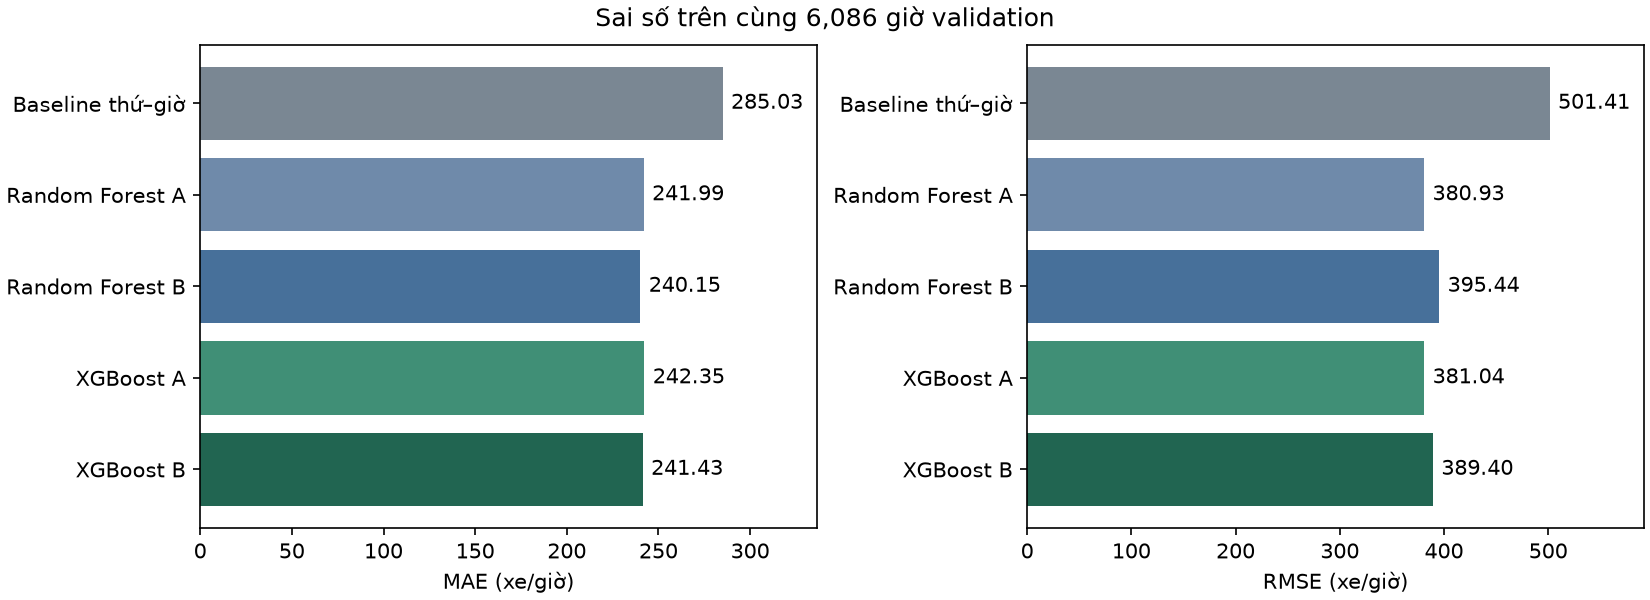

In [5]:
outputs = experiment / "outputs"
figures = experiment / "figures"
outputs.mkdir(exist_ok=True)
figures.mkdir(exist_ok=True)
fold_manifest.to_csv(outputs / "cv_folds.csv", index=False)
fold_scores.to_csv(outputs / "cv_fold_scores.csv", index=False)
summary.to_csv(outputs / "cv_summary.csv", index=False)
validation_metrics.to_csv(outputs / "validation_metrics.csv")
predictions.to_csv(outputs / "validation_predictions.csv")
daily.to_csv(outputs / "validation_daily_sse.csv")

with data_path.open("rb") as stream:
    data_hash = file_digest(stream, "sha256").hexdigest()
run_config = {
    "dataset": data_path.relative_to(project).as_posix(),
    "dataset_sha256": data_hash,
    "data_params": data_params,
    "split_boundaries": {
        name: {
            "first": str(part["date_time"].min()),
            "last": str(part["date_time"].max()),
            "n_hours": len(part),
        }
        for name, part in splits.items()
    },
    "evaluation": "validation",
    "selection": "lowest arithmetic mean of RMSE across 3 TimeSeriesSplit folds on train",
    "weather_assumption": "Same-hour weather is available at prediction time.",
    "features": features,
    "parameter_grid": grid,
    "fixed_params": fixed_params,
    "chosen_params": chosen,
    "reference_predictions": (reference / "validation_predictions.csv").relative_to(project).as_posix(),
    "versions": {"pandas": pd.__version__, "sklearn": sklearn.__version__, "xgboost": xgboost.__version__},
}
(outputs / "run_config.json").write_text(
    json.dumps(run_config, indent=2, ensure_ascii=False) + "\n", encoding="utf-8"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
colors = ["#7A8793", "#6F8AAA", "#47709A", "#408F76", "#216551"]
for ax, metric in zip(axes, ("MAE", "RMSE")):
    scores = validation_metrics[metric]
    bars = ax.barh(scores.index, scores, color=colors)
    ax.bar_label(bars, fmt="%.2f", padding=4)
    ax.invert_yaxis()
    ax.set_xlim(0, scores.max() * 1.18)
    ax.set_xlabel(f"{metric} (xe/giờ)")
fig.suptitle(f"Sai số trên cùng {len(validation):,} giờ validation")
figure = figures / "validation_metrics.png"
fig.savefig(figure, dpi=150)
plt.close(fig)
display(Image(filename=str(figure)))

<!-- proposal-assessment -->
## Đánh giá đối với proposal — RQ_2, RQ_3

**Vai trò: CHÍNH.** Mã đối chiếu: [E18](../../docs/experiment_tracking/EXPERIMENTS_BY_DATE_AND_RQ.md). 

- **Câu hỏi:** Tuning A/B ngang nhau theo RMSE có thay đổi kết luận thời tiết không; lỗi lớn ở đâu?
- **Đánh giá:** Trực tiếp kiểm tra weather với A/B tuning ngang nhau theo RMSE (12 ứng viên×3 fold mỗi nhánh), đồng thời lưu daily SSE cho RQ_3. A→B: MAE 242,348→241,431 nhưng RMSE 381,038→389,401; chưa có lợi ích RMSE trong protocol này.
- **Giới hạn kết luận:** Seed42 và một validation chưa đủ kiểm tra độ bền theo mùa. Các dòng RF là đối chứng đọc lại, không phải RF chạy mới; các ngày SSE lớn chỉ là mô tả lỗi, không tự chứng minh nguyên nhân.
- **Bằng chứng:** [E18: run_config.json](outputs/run_config.json).

Đánh giá trên dựa vào hiện vật lịch sử đã đối chứng, không phải kết quả chạy mới. Code lấy dữ liệu đã được chuẩn hóa; chưa huấn luyện lại hoặc chấm test.
